# Nearest Neighbors

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import make_classification, make_regression
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import precision_score, recall_score, mean_squared_error

## K-Nearest Neighbors

**KNN** is an non-parametric supervised learning algorithm that can be used for both classification and regression. In classification, it aims to assign samples to classes based on their nearest neighbors in space, the sample being usually classified as whatever is the majority class among the neighbors. For regression, the output is usually the average of the values of the neighbors.

The nearest neighbors are identified based on some notion of distance, usually **Euclidean distance**.

The algorithm generally works as follows:
1. Given as input:
    - Training data
    - A test sample
    - $k$ (the number of classes)
2. For each training item, calculate the distance to the test sample
3. Sort the distances in ascending order
4. Take top $k$ training items:
    - **Classification:** Output the majority class of the $k$ training items (random if there's a tie)
    - **Regression:** Output the mean value for the $k$ training items

In [2]:
class KNN:
    def __init__(self, k):
        self.k = k
        self.X = None
        self.y = None

    def fit(self, X, y):
        self.X = X
        self.y = y.reshape(-1, 1)
        return self

    def _nearest_targets(self, X):
        # calculate Euclidean distance
        # the training and testing data may have a different number of samples, so we use a little trick where we change the axes to still be able
        # to take advantage of numpy's fast processing when computing the Euclidean distances
        # [:, None, :] adds a new axis, changing the shape e.g. (10, 2) -> (10, 1, 2)
        # [None, :, :] changes e.g. (2, 2) -> (1, 2, 2)
        # broadcasting automatically expands them to the same shape, allowing elementwise subtraction
        diff = self.X[:, None, :] - X[None, :, :]
        # taking the norm along axis=2 computes the Euclidean distance for each pair of points
        dist = np.linalg.norm(diff, axis=2)
        # get the indices of the top k nearest neighbors
        idx = np.argpartition(dist, self.k, axis=0)
        idx = idx[:self.k, :]
        # get the list of target values for nearest neighbors
        y = self.y[idx, np.arange(self.y.shape[1])]
        return y
        

class KNNClf(KNN):
    def __init__(self, k):
        self.k = k
        self.X = None
        self.y = None

    def predict(self, X):
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        y = self._nearest_targets(X)
        # compute mode per column
        modes = []
        for col in y.T:
            vals, counts = np.unique(col, return_counts=True)
            modes.append(vals[np.argmax(counts)])
        modes = np.array(modes)
        return modes

class KNNReg(KNN):
    def __init__(self, k):
        self.k = k
        self.X = None
        self.y = None

    def predict(self, X):
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        y = self._nearest_targets(X)
        return np.mean(y, axis=0)

def plot_decision_boundary(model, X, y):
    cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
    cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])
    h = .02  # step size in the mesh
    # Plot the decision boundary. For that, we will assign a color to each
    # point in the mesh [x_min, x_max]x[y_min, y_max].
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    # Put the result into a color plot
    Z = Z.reshape(xx.shape)
    plt.figure()
    plt.pcolormesh(xx, yy, Z, cmap=cmap_light)
    # Plot also the training points
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title("Decision Boundary")

#### Test KNN Classifier

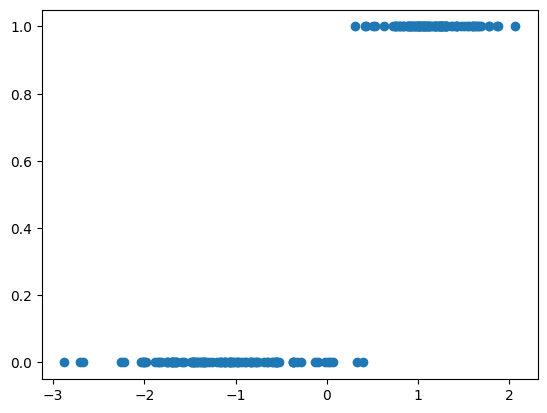

In [3]:
X, y = make_classification(n_samples=200, n_features=1, n_informative=1, n_redundant=0, n_repeated=0, n_classes=2,
                           n_clusters_per_class=1, class_sep=1.2, random_state=1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)
plt.scatter(X, y);

In [5]:
knn = KNNClf(k=3).fit(X_train, y_train)
knn2 = KNeighborsClassifier(n_neighbors=3, algorithm='brute', weights='uniform').fit(X_train, y_train)

In [6]:
precision_score(y_test, knn.predict(X_test)), precision_score(y_test, knn2.predict(X_test))

(0.9523809523809523, 0.9523809523809523)

In [7]:
recall_score(y_test, knn.predict(X_test)), recall_score(y_test, knn2.predict(X_test))

(1.0, 1.0)

In [10]:
X, y = make_classification(n_samples=200, n_features=2, n_informative=2, n_redundant=0, n_repeated=0, n_classes=2,
                           n_clusters_per_class=1, class_sep=1.2, random_state=1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((160, 2), (160,), (40, 2), (40,))

In [11]:
knn = KNNClf(k=3).fit(X_train, y_train)
knn2 = KNeighborsClassifier(n_neighbors=3, algorithm='brute', weights='uniform').fit(X_train, y_train)

In [12]:
precision_score(y_test, knn.predict(X_test)), precision_score(y_test, knn2.predict(X_test))

(0.9130434782608695, 0.9130434782608695)

In [13]:
recall_score(y_test, knn.predict(X_test)), recall_score(y_test, knn2.predict(X_test))

(1.0, 1.0)

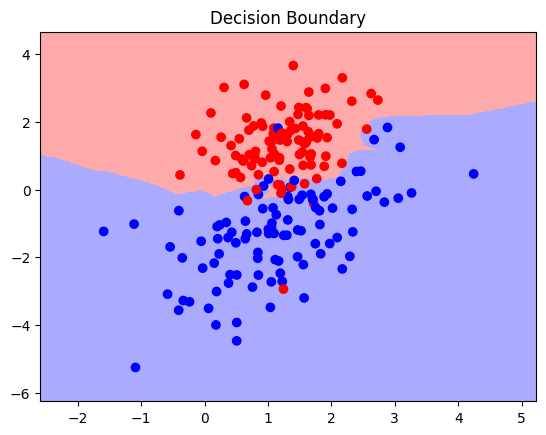

In [14]:
plot_decision_boundary(knn, X, y)

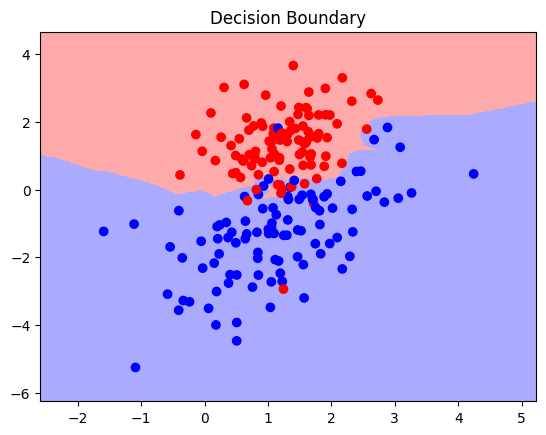

In [15]:
plot_decision_boundary(knn2, X, y)

#### Test KNN Regressor

In [16]:
X, y = make_regression(n_samples=200, n_features=3, n_informative=3, n_targets=1, bias=0.0, noise=0.0, random_state=1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [17]:
knn = KNNReg(k=3).fit(X_train, y_train)
knn2 = KNeighborsRegressor(n_neighbors=3, algorithm='brute', weights='uniform').fit(X_train, y_train)

In [18]:
knn.predict(X_test)[:10]

array([-143.66347086,   -5.51310332,   39.05828504,   65.77992417,
         65.84569493,   86.68234972,   -9.48594322,   43.08439024,
          0.83241197,   30.90114087])

In [19]:
knn2.predict(X_test)[:10]

array([-143.66347086,   -5.51310332,   39.05828504,   65.77992417,
         65.84569493,   86.68234972,   -9.48594322,   43.08439024,
          0.83241197,   30.90114087])

In [22]:
mean_squared_error(y_test, knn.predict(X_test)), mean_squared_error(y_test, knn2.predict(X_test))

(639.5953606881485, 639.5953606881485)